# 05 — Második intelligenciaréteg: tematikus kategorizálás / Layer 2: thematic categorisation

HU: Az első réteg megmondja, **milyen** egy mondat (negatív / semleges / pozitív). A második réteg két szinten
mondja meg, **miről** és **pontosan mi miatt**:

```
mondat ──► [1. réteg] szentiment (B)              → negatív / semleges / pozitív
       ──► [2/a] aspektus-osztályozó (HRAST, BERT) → MIRŐL szól?   pl. bathroom
       ──► [2/b] altémák (beágyazás + fürtözés)    → MI A GOND?    pl. „nincs meleg víz”
```

| # | Lépés / Step | Mérés / Measurement | Dolgozat / Thesis |
|---|---|---|---|
| 1 | 2/a tanítás a HRAST-on / training on HRAST | aspektusonkénti F1 a HRAST-teszten, vs. kulcsszólista | 3.4, 3.5 |
| 2 | 2/a alkalmazás a Booking-mondatokra / applying to Booking | egyezés a kulcsszólistával | 3.5 |
| 3 | 2/b altémák aspektusonként / subtopics per aspect | NPMI-koherencia, diverzitás, stabilitás (ARI) | 3.4, 3.5 |
| 4 | Panasztérkép / complaint map | lift szegmensenként | 3.5 |
| 5 | Kézi ellenőrzés / manual check | témánkénti pontosság | 3.5 |

**Előfeltétel / Prerequisites:** a 02-es notebook által mentett `data/labels/sentences_B`, a HRAST CSV a `data/raw/hrast/`
mappában, és `pip install sentence-transformers umap-learn`. GPU ajánlott (a 2/a tanítás kb. 10–15 perc).

## 1. Környezet és adatok / Environment and data

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# HU: Mondatszintű (B)-címkék + a vélemények metaadatai (szegmensekhez).
# EN: Sentence-level (B) labels + review metadata (for the segments).
sent = dl.read_frame(PATHS.labels / "sentences_B")
meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
print(f"{len(sent):,} sentences from {sent['review_id'].nunique():,} reviews")
display(sent["B_label"].value_counts(normalize=True).round(3).to_frame("sentence-level share"))

89,948 sentences from 20,000 reviews


,sentence-level share
B_label,
positive,0.745
negative,0.210
neutral,0.045


## 2. 2/a — Aspektus-osztályozó a HRAST-on / Aspect classifier on HRAST

HU: Többcímkés BERT: aspektusonként egy igen/nem döntés (szigmoid). A ritka aspektusok nagyobb súlyt kapnak
(`pos_weight`), a döntési küszöböt aspektusonként a **validációs** halmazon hangoljuk, a végső mérés a **teszthalmazon**
történik — és ugyanott mérjük a kulcsszólistát is (alapvonal).

EN: Multi-label BERT: one yes/no decision per aspect (sigmoid). Rare aspects get a larger weight (`pos_weight`), the
decision threshold is tuned per aspect on the **validation** set, the final measurement is on the **test** set — where
the keyword list (baseline) is measured too.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

14:25:37 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
14:25:37 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


14:25:37 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

14:26:22 | INFO    | src.aspect_model | Aspect split — train 16173 | val 3466 | test 3466
14:26:22 | INFO    | httpx | HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
14:26:23 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
14:26:23 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/bert-base-uncased/resolve/main/tokenizer_config.json "HTTP/1.1 200 OK"
14:26:23 | WARNING | huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
14:26:23 | INFO    | httpx | HTTP Request: GET https://huggingface.co/api/models/bert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 307 Temporary Redirect"
14:26:23 | INFO    | httpx | HTTP Request: GET https://huggingface.co/api/models/google-bert/bert-base-uncased/tree/main/additional_chat_temp

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
14:26:25 | INFO    | s

Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro
1,0.323661,0.290268,0.796862,0.799208
2,0.222698,0.207442,0.843427,0.829487
3,0.181165,0.191318,0.855863,0.843011


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

14:37:41 | INFO    | src.aspect_model | Aspect model saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\aspect_model_hrast (11.1 min) | test micro-F1 0.8768 | macro-F1 0.8622
14:37:41 | INFO    | src.evaluation | Table saved: 05_aspect_model_test_report.csv
14:37:41 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_vs_model.csv


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


14:37:42 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


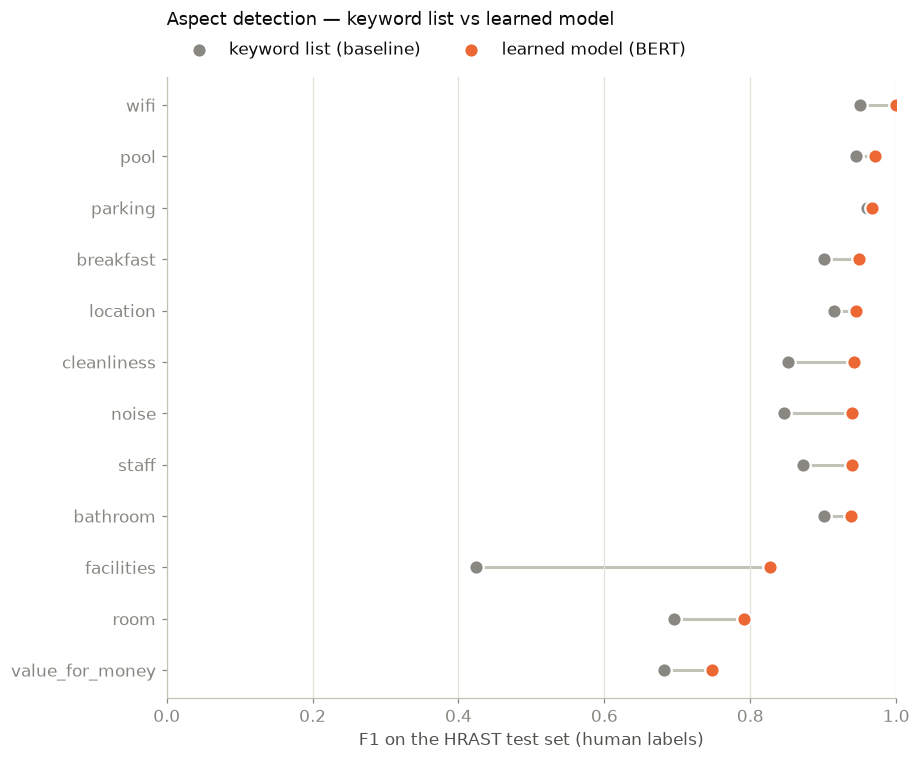

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# HU: Ha a modell már elkészült, nem tanítjuk újra (a mentett teszteredményt töltjük be).
# EN: If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. 2/a alkalmazása a Booking-mondatokra / Applying 2/a to the Booking sentences

HU: Darabolt, folytatható futás (mint a címkézésnél). Itt nincs emberi címke, ezért a kulcsszólistával való
**egyezést** mérjük (konzisztencia), nem a pontosságot.
EN: Chunked, resumable run (as in labelling). There is no human label here, so we measure **agreement** with the
keyword list (consistency), not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_sentence")
dl.write_frame(sent_asp, PATHS.labels / "sentences_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

15:24:25 | INFO    | src.bert_labelling | [aspects_sentence] chunk 1/9 (10000 texts)
15:24:34 | INFO    | src.bert_labelling | [aspects_sentence] chunk 2/9 (10000 texts)
15:24:42 | INFO    | src.bert_labelling | [aspects_sentence] chunk 3/9 (10000 texts)
15:24:50 | INFO    | src.bert_labelling | [aspects_sentence] chunk 4/9 (10000 texts)
15:24:59 | INFO    | src.bert_labelling | [aspects_sentence] chunk 5/9 (10000 texts)
15:25:07 | INFO    | src.bert_labelling | [aspects_sentence] chunk 6/9 (10000 texts)
15:25:16 | INFO    | src.bert_labelling | [aspects_sentence] chunk 7/9 (10000 texts)
15:25:24 | INFO    | src.bert_labelling | [aspects_sentence] chunk 8/9 (10000 texts)
15:25:33 | INFO    | src.bert_labelling | [aspects_sentence] chunk 9/9 (9948 texts)
15:25:42 | INFO    | src.aspect_model | Aspects predicted for 89948 sentences | without aspect: 2.0%


,share of sentences
generic,0.2702
location,0.2530
staff,0.1926
room,0.1702
comfort,0.1122
cleanliness,0.1095
facilities,0.1068
breakfast,0.1020
value_for_money,0.0549
bed,0.0523


Sentences without any aspect: 2.0%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,529,0.0059,0.6181,0.0813,0.3006,2.9442,0.4037
bathroom,4325,0.0481,0.4763,0.0483,0.4754,2.2686,0.6384
wifi,763,0.0085,0.4102,0.0564,0.5334,1.9539,0.7164
noise,3662,0.0407,0.3779,0.0451,0.5770,1.8001,0.7749
facilities,9610,0.1068,0.3609,0.0557,0.5835,1.7188,0.7836
reception,2943,0.0327,0.3282,0.0567,0.6150,1.5634,0.8260
parking,1734,0.0193,0.2630,0.0709,0.6661,1.2525,0.8945
bed,4700,0.0523,0.2511,0.0366,0.7123,1.1958,0.9567
bar,778,0.0086,0.2416,0.0476,0.7108,1.1509,0.9546


15:26:05 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
15:26:07 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


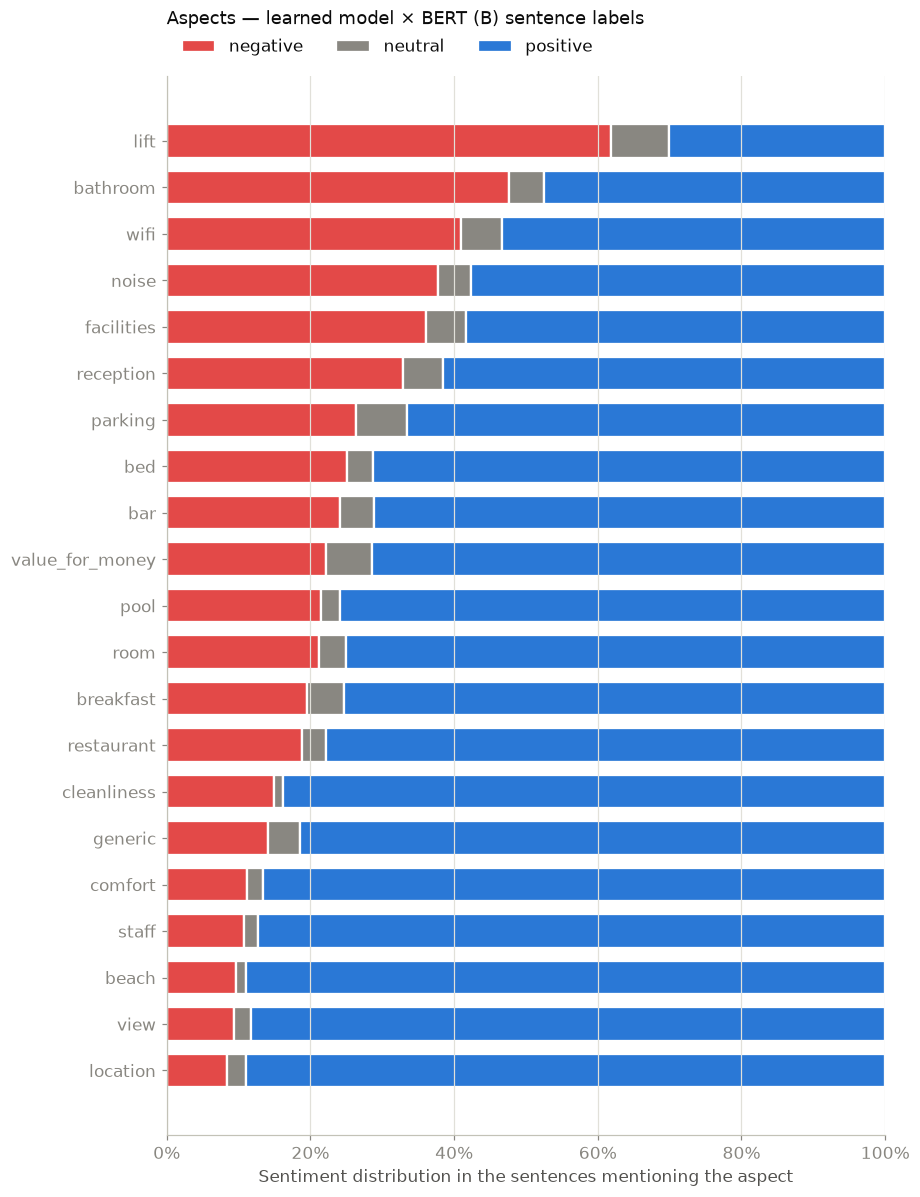

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2526,0.1973,0.9214,0.7757
staff,0.1929,0.1366,0.9280,0.7398
room,0.1720,0.2204,0.8750,0.6052
cleanliness,0.1083,0.0995,0.9847,0.9177
facilities,0.1079,0.0702,0.8951,0.3566
breakfast,0.1024,0.1169,0.9672,0.8323
value_for_money,0.0558,0.0512,0.9801,0.8037
bathroom,0.0474,0.0525,0.9827,0.8176
noise,0.0415,0.0351,0.9904,0.8695


15:26:12 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# HU: Aspektus × szentiment a TANULT aspektusokkal (vö. 04-es notebook: kulcsszavas változat).
# EN: Aspect × sentiment with the LEARNED aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b — Altémák aspektusonként / Subtopics per aspect

HU: A választott szentimentű (alapból **negatív**) mondatokon minden aspektusra külön témamodell: Sentence-BERT
beágyazás → UMAP → HDBSCAN → c-TF-IDF. A dicséretek altémáihoz állítsd `SENTIMENT = "positive"`-ra, és futtasd
újra innen (a fájlnevek a szentimentet is tartalmazzák).
EN: On sentences of the chosen sentiment (**negative** by default) a separate topic model per aspect: Sentence-BERT
embedding → UMAP → HDBSCAN → c-TF-IDF. For the subtopics of praise set `SENTIMENT = "positive"` and re-run from here
(file names include the sentiment).

In [6]:
SENTIMENT = "negative"
subset = sent_asp[(sent_asp["B_label"] == SENTIMENT) & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} sentences with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}")
print("Embeddings:", embeddings.shape)

18,035 negative sentences with at least one aspect


15:27:51 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
15:27:51 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
15:27:52 | INFO    | httpx | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\seszt\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
15:27:52 | INFO    | httpx | HTTP Request: HEAD https://huggin

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

15:27:52 | INFO    | sentence_transformers.base.model | Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
15:27:52 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
15:27:52 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/config_sentence_transformers.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fconfig_sentence_transformers.json=&etag=%22fd1b291129c607e5d49799f87cb219b27f98acdf%22 "HTTP/1.1 200 OK"
15:27:52 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
15:27:52 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-

... (17 outputs left out)

15:28:02 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/chat_template.jinja "HTTP/1.1 404 Not Found"
15:28:02 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/1_Pooling/config.json "HTTP/1.1 307 Temporary Redirect"
15:28:03 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/1_Pooling%2Fconfig.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2F1_Pooling%2Fconfig.json=&etag=%22d1514c3162bbe87b343f565fadc62e6c06f04f03%22 "HTTP/1.1 200 OK"
15:28:03 | INFO    | httpx | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/1_Pooling%2Fconfig.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2F1_Pooling%2Fconfig.json=&etag=%22

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

15:28:03 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/2_Normalize/config.json "HTTP/1.1 404 Not Found"
15:28:03 | INFO    | httpx | HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2 "HTTP/1.1 200 OK"
15:28:04 | INFO    | src.bert_labelling | [emb_negative] chunk 1/2 (10000 texts)
15:28:10 | INFO    | src.bert_labelling | [emb_negative] chunk 2/2 (8035 texts)


Embeddings: (18035, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:30:16 | INFO    | src.topic_modeling | Topics: 26 | noise 19.0% -> 8.1% | NPMI 0.057 | diversity 0.892


,value
n_sentences,18035.0000
n_topics,26.0000
min_cluster_size,180.0000
noise_share_before,0.1900
noise_share_after,0.0814
mean_coherence_npmi,0.0567
topic_diversity,0.8923


,topic,size,share,label,top_terms,coherence_npmi,examples
0,0,2032,0.112670,breakfast / food / restaurant,"breakfast, food, restaurant, not, bar, good, no, dinner, options, eat",0.108672,"We didn't have breakfast, as it didn't look great for the price quoted, and there were other options very nearby. ||..."
1,1,1526,0.084613,shower / bathroom / water,"shower, bathroom, water, toilet, hot, bath, hot water, small, pressure, wet",0.199956,"the shower/bathroom was like a stall. || The bathroom was very small, it may be hard to take a proper shower in ther..."
2,2,1178,0.065317,noise / noisy / hear,"noise, noisy, hear, loud, night, sleep, music, sound, people, street",0.201040,"The sound isolation was bad, I could hear noises from all rooms nearby. || Room was noisy when I wanted to rest due ..."
3,3,1007,0.055836,bed / beds / pillows,"bed, beds, pillows, comfortable, mattress, uncomfortable, hard, soft, not comfortable, sofa",0.237138,"The bed and pillows weren’t very comfortable || The beds were very had, pillows very uncomfortable. || The bed was a..."
4,4,1187,0.065816,room / rooms / small,"room, rooms, small, room small, property, old, space, building, apartment, tired",-0.001693,Rooms very small. || The rooms are a bit small. || Rooms too small.
5,5,844,0.046798,staff / check / reception,"staff, check, reception, desk, friendly, not, time, rude, service, english",0.132159,"The staff was a little lost, like, over busy and you could easily make a line at the reception for check in and chec..."
6,6,696,0.038592,air / air conditioning / conditioning,"air, air conditioning, conditioning, ac, cold, room, hot, warm, heating, fan",0.249750,"Air conditioning didn't seem to cool the room down much. || The room got pretty warm, no AC. || The air-conditioning..."
7,7,752,0.041697,clean / cleaning / dirty,"clean, cleaning, dirty, cleaned, carpet, room, furniture, housekeeping, not clean, not",0.053122,The room wasn's cleaned during our stay. || The room was not very clean. || The room was not properly cleaned.
8,8,899,0.049848,hotels / not / star,"hotels, not, star, like, expensive, resort, hostel, location, price, night",0.023600,I could not recommend this hotel enough. || Could not recommend this hotel enough. || Hotel was very nice but I felt...
9,9,738,0.040920,location / walk / airport,"location, walk, airport, far, taxi, town, shuttle, walking, bus, station",0.220935,Location is good but if take a taxi it can a bit stucked. || The location is little bit away from the center and mai...


15:30:16 | INFO    | src.evaluation | Table saved: 05_negative_topics_overview.csv
15:30:17 | INFO    | src.evaluation | Figure saved: 05_negative_topics_overview.png


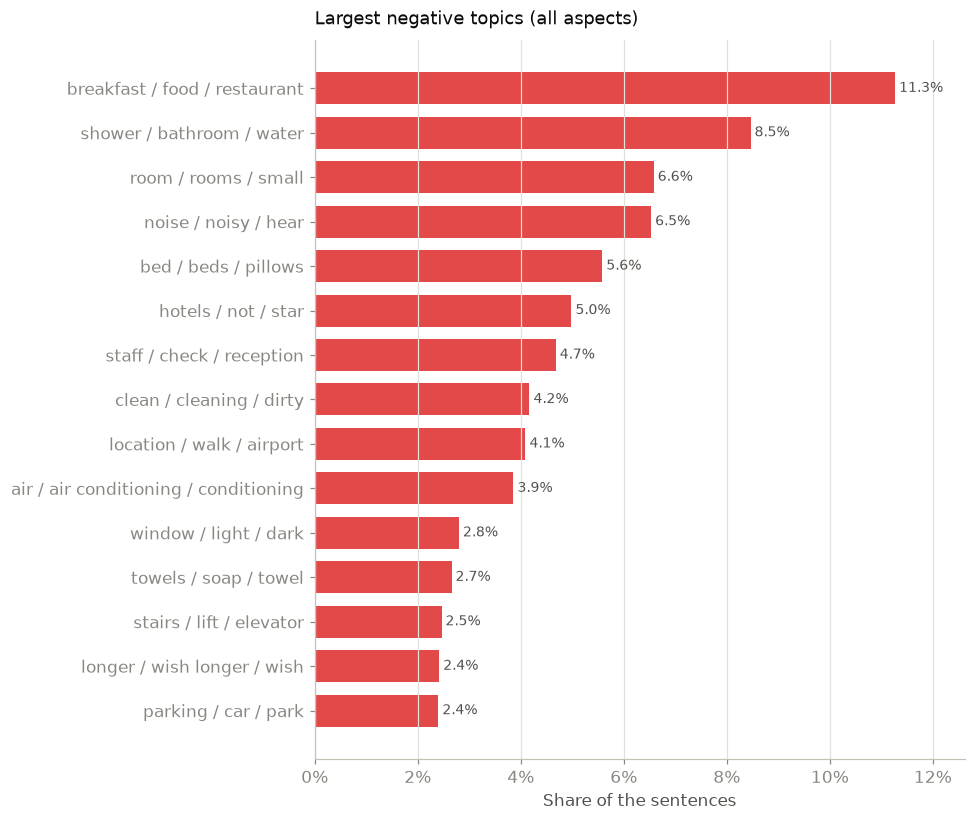

In [7]:
# HU: Áttekintő témamodell az összes ilyen mondaton (mintán) — aspektustól függetlenül.
# EN: Overview topic model on all such sentences (on a sample) — independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{SENTIMENT}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{SENTIMENT}_topics_overview"); plt.show()

15:32:55 | INFO    | src.topic_modeling | room             3242 sentences
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:33:38 | INFO    | src.topic_modeling | Topics: 21 | noise 29.3% -> 2.7% | NPMI -0.071 | diversity 0.800
15:33:38 | INFO    | src.topic_modeling | location         1922 sentences
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:33:50 | INFO    | src.topic_modeling | Topics: 3 | noise 7.9% -> 4.3% | NPMI -0.074 | diversity 0.867
15:33:50 | INFO    | src.topic_modeling | staff            1867 sentences
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridd

,n_sentences,n_topics,min_cluster_size,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,
room,3242,21,40,0.2933,0.0271,-0.0707,0.8000
location,1922,3,40,0.0786,0.0427,-0.0741,0.8667
staff,1867,11,40,0.3305,0.1484,-0.1378,0.8091
cleanliness,1469,11,40,0.3390,0.0436,-0.0989,0.7273
facilities,3468,21,40,0.1805,0.0698,-0.0343,0.8524
comfort,1127,5,40,0.1686,0.0195,-0.0508,0.7400
breakfast,1795,2,40,0.0000,0.0000,0.0303,0.8500
bathroom,2060,14,40,0.2704,0.0121,-0.0141,0.7643
noise,1384,11,40,0.4010,0.0347,-0.0322,0.6818


15:35:46 | INFO    | src.evaluation | Table saved: 05_negative_subtopic_quality.csv
15:35:46 | INFO    | src.evaluation | Table saved: 05_negative_subtopics.csv


Main aspects: ['facilities', 'room', 'bathroom', 'location', 'staff', 'breakfast', 'cleanliness', 'noise', 'bed', 'comfort', 'value_for_money', 'reception', 'pool', 'parking', 'restaurant', 'lift', 'wifi']


15:35:52 | INFO    | src.evaluation | Figure saved: 05_negative_subtopics_by_aspect.png


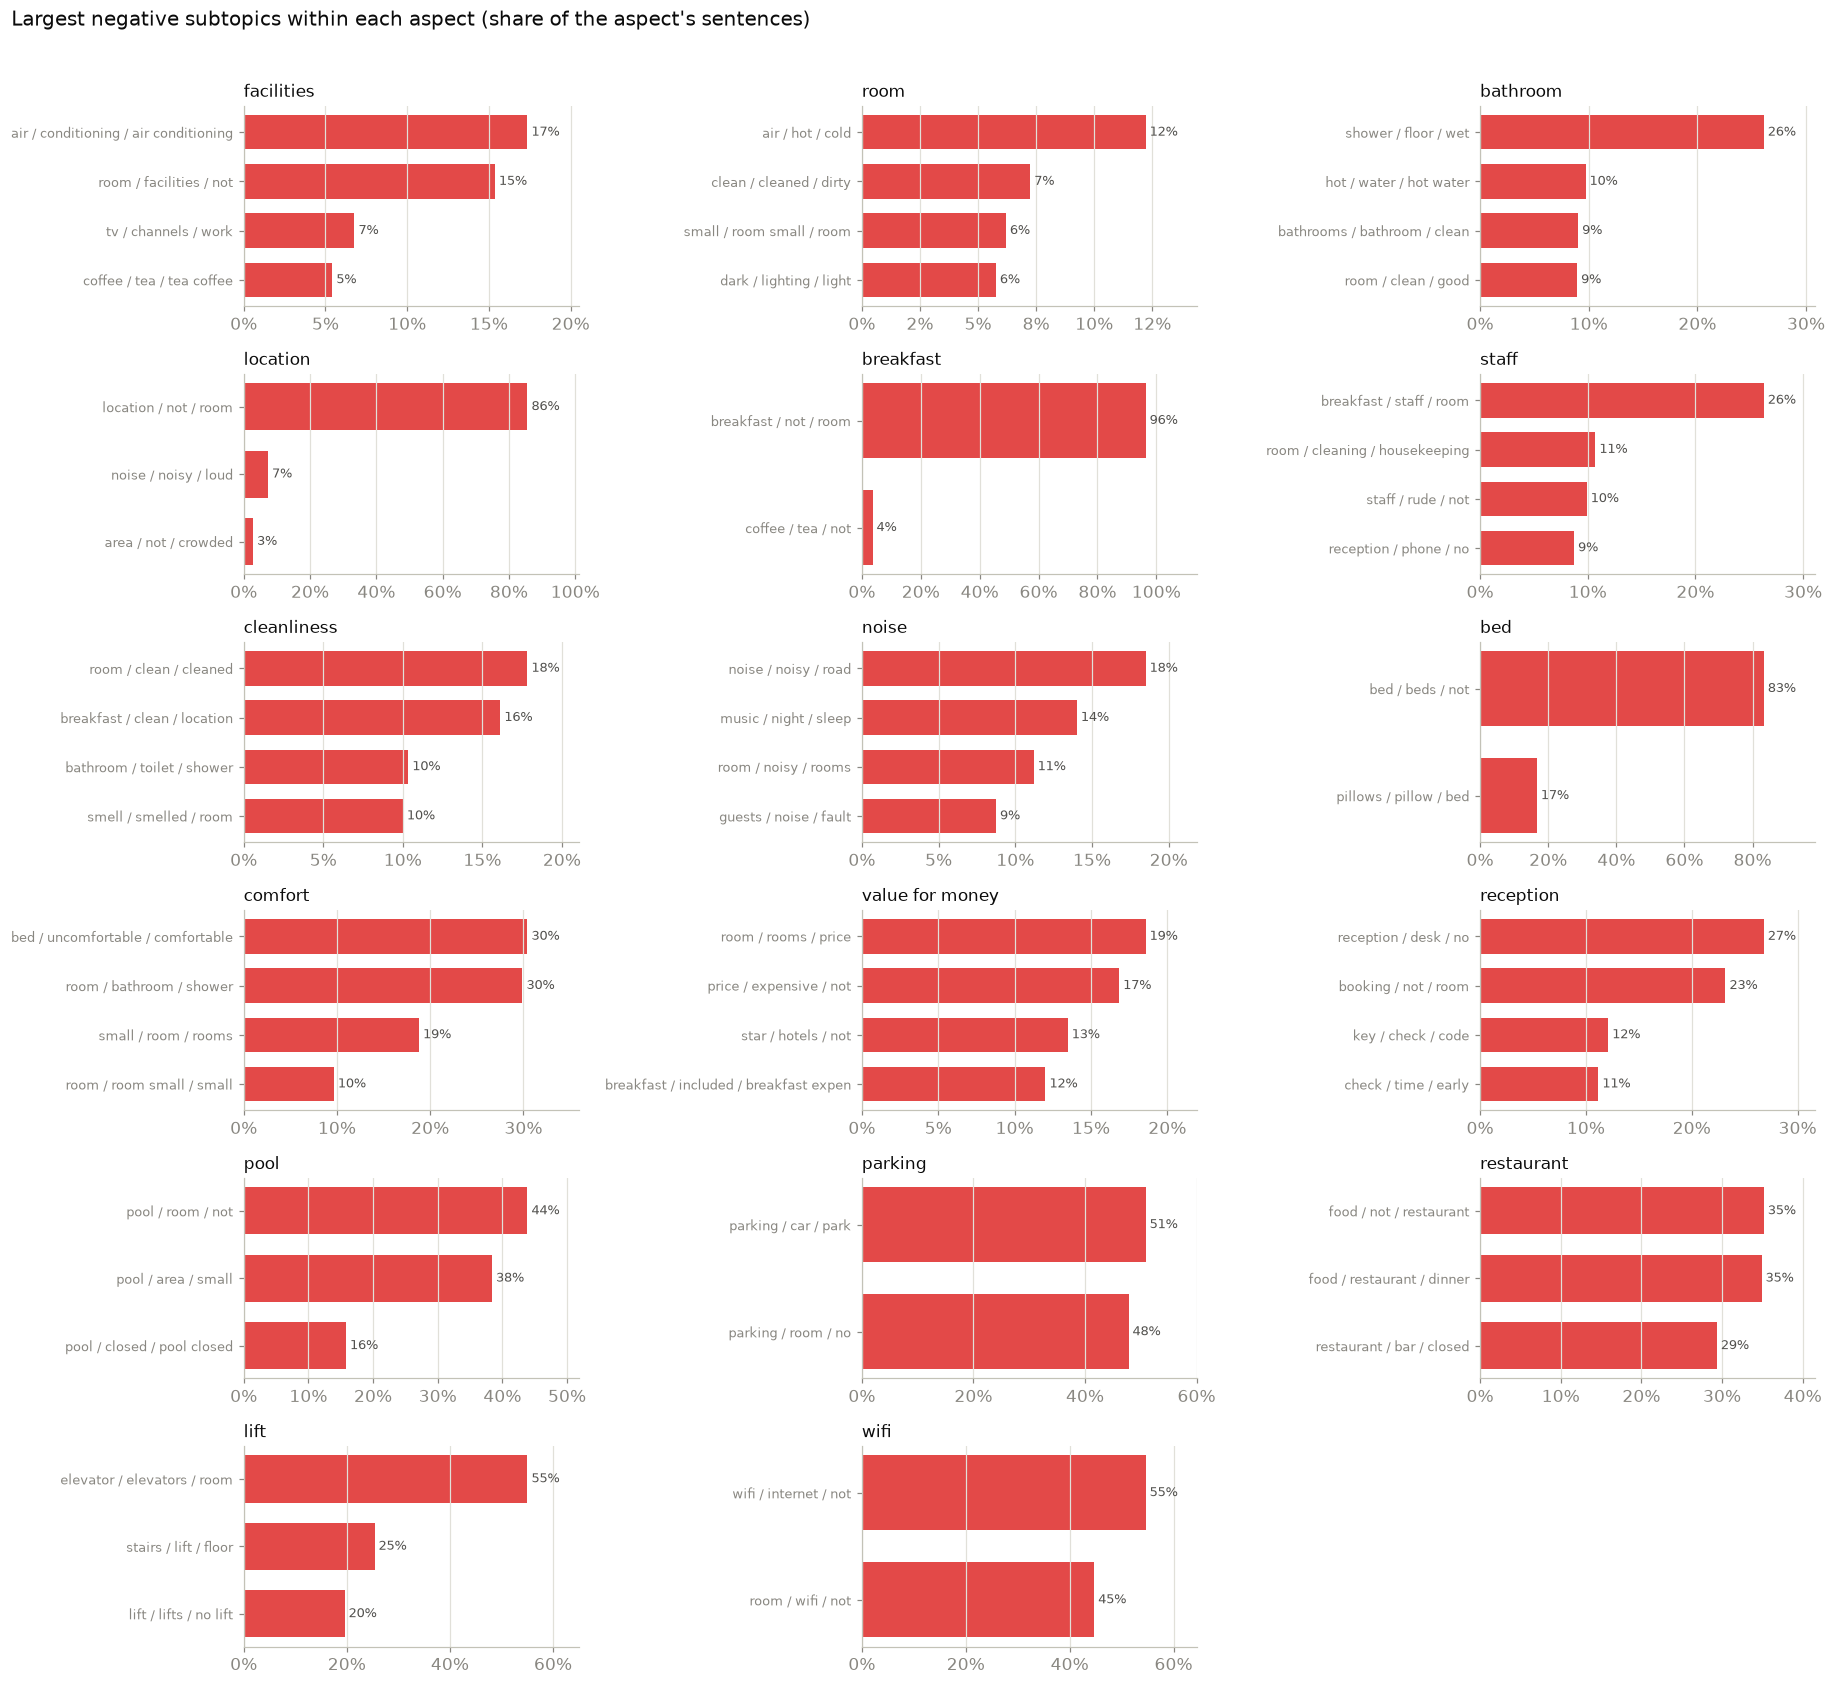

In [8]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{SENTIMENT}_subtopic_quality")
# HU: A legtöbb mondatú, legalább egy altémát adó aspektusok. / EN: Aspects with most sentences and at least one subtopic.
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{SENTIMENT}_subtopics")
dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{SENTIMENT}")

tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{SENTIMENT}_subtopics_by_aspect"); plt.show()

In [11]:
# HU: Olvasd el az altémákat a példamondatokkal! / EN: Read the subtopics with the example sentences!
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f})")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== facilities ===
  [0] air / conditioning / air conditioning  (17%, NPMI 0.13)
       e.g. Air conditioning didn't seem to cool the room down much.
  [1] room / facilities / not  (15%, NPMI 0.10)
       e.g. Lack of amenities (was basically a set of rooms over a bar).
  [2] tv / channels / work  (7%, NPMI -0.05)
       e.g. The tv in the room couldn’t be cast to and didn’t have wi-fi so you could only watch a few channels.
  [3] towels / towel / hang  (5%, NPMI -0.09)
       e.g. Some towels were too worn-out.
  [4] kitchen / cutlery / utensils  (5%, NPMI 0.04)
       e.g. The kitchen was not well equipped, we were missing basic cooking equipment (proper knives, cutting boards, kitchen towels, basic spices, coffee machin
  [5] coffee / tea / tea coffee  (5%, NPMI 0.20)
       e.g. No tea/coffee facilities in the room which would have been great.

=== room ===
  [0] air / hot / cold  (12%, NPMI 0.12)
       e.g. The room was very warm, the air circulator was not functioning well.
  [

In [10]:
# HU: OPCIONÁLIS: beszédes nevek a dolgozatba (a témaszámokat a fenti listából vedd).
# EN: OPTIONAL: meaningful names for the thesis (take the topic numbers from the list above).
TOPIC_NAMES = {
    # ("bathroom", 0): "no hot water",
    # ("noise", 1): "thin walls / neighbours",
}
if TOPIC_NAMES:
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{SENTIMENT}_subtopics")

### Stabilitás / Stability

HU: Ugyanaz a modell három különböző véletlen kezdőértékkel a három legnagyobb aspektuson. A korrigált Rand-index
(ARI) 0,5 felett azt jelzi, hogy a témák nem a véletlen termékei.
EN: The same model with three different random seeds on the three largest aspects. An adjusted Rand index (ARI)
above 0.5 shows that the topics are not products of chance.

In [12]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows])
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{SENTIMENT}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:42:02 | INFO    | src.topic_modeling | Topics: 21 | noise 18.1% -> 7.0% | NPMI -0.034 | diversity 0.852
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:42:37 | INFO    | src.topic_modeling | Topics: 19 | noise 18.1% -> 6.7% | NPMI -0.055 | diversity 0.874
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:43:12 | INFO    | src.topic_modeling | Topics: 19 | noise 18.5% -> 7.0% | NPMI -0.037 | diversity 0.868
15:43:12 | INFO    | src.topic_modeling | S

,mean_pairwise_ari,n_topics_per_seed
aspect,,
facilities,0.899,"[21, 19, 19]"
room,0.857,"[21, 23, 23]"
bathroom,0.808,"[14, 13, 12]"


15:45:30 | INFO    | src.evaluation | Table saved: 05_negative_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_negative_subtopic_stability.csv')

## 5. Panasztérkép / Complaint map

HU: Egy aspektus altémáinak aránya szegmensenként, liftként: 1 felett az altéma az adott szegmensben gyakoribb,
mint átlagosan. Például: a szállodákban a „vékony fal” vagy az apartmanokban a „nincs meleg víz” a jellemzőbb?
EN: Share of an aspect's subtopics per segment, as lift: above 1 the subtopic is more common in that segment than on
average. E.g.: is "thin walls" more typical in hotels, or "no hot water" in apartments?

15:45:57 | INFO    | src.evaluation | Table saved: 05_negative_map_facilities_by_accommodation_type.csv
15:46:02 | INFO    | src.evaluation | Figure saved: 05_negative_map_facilities_by_accommodation_type.png


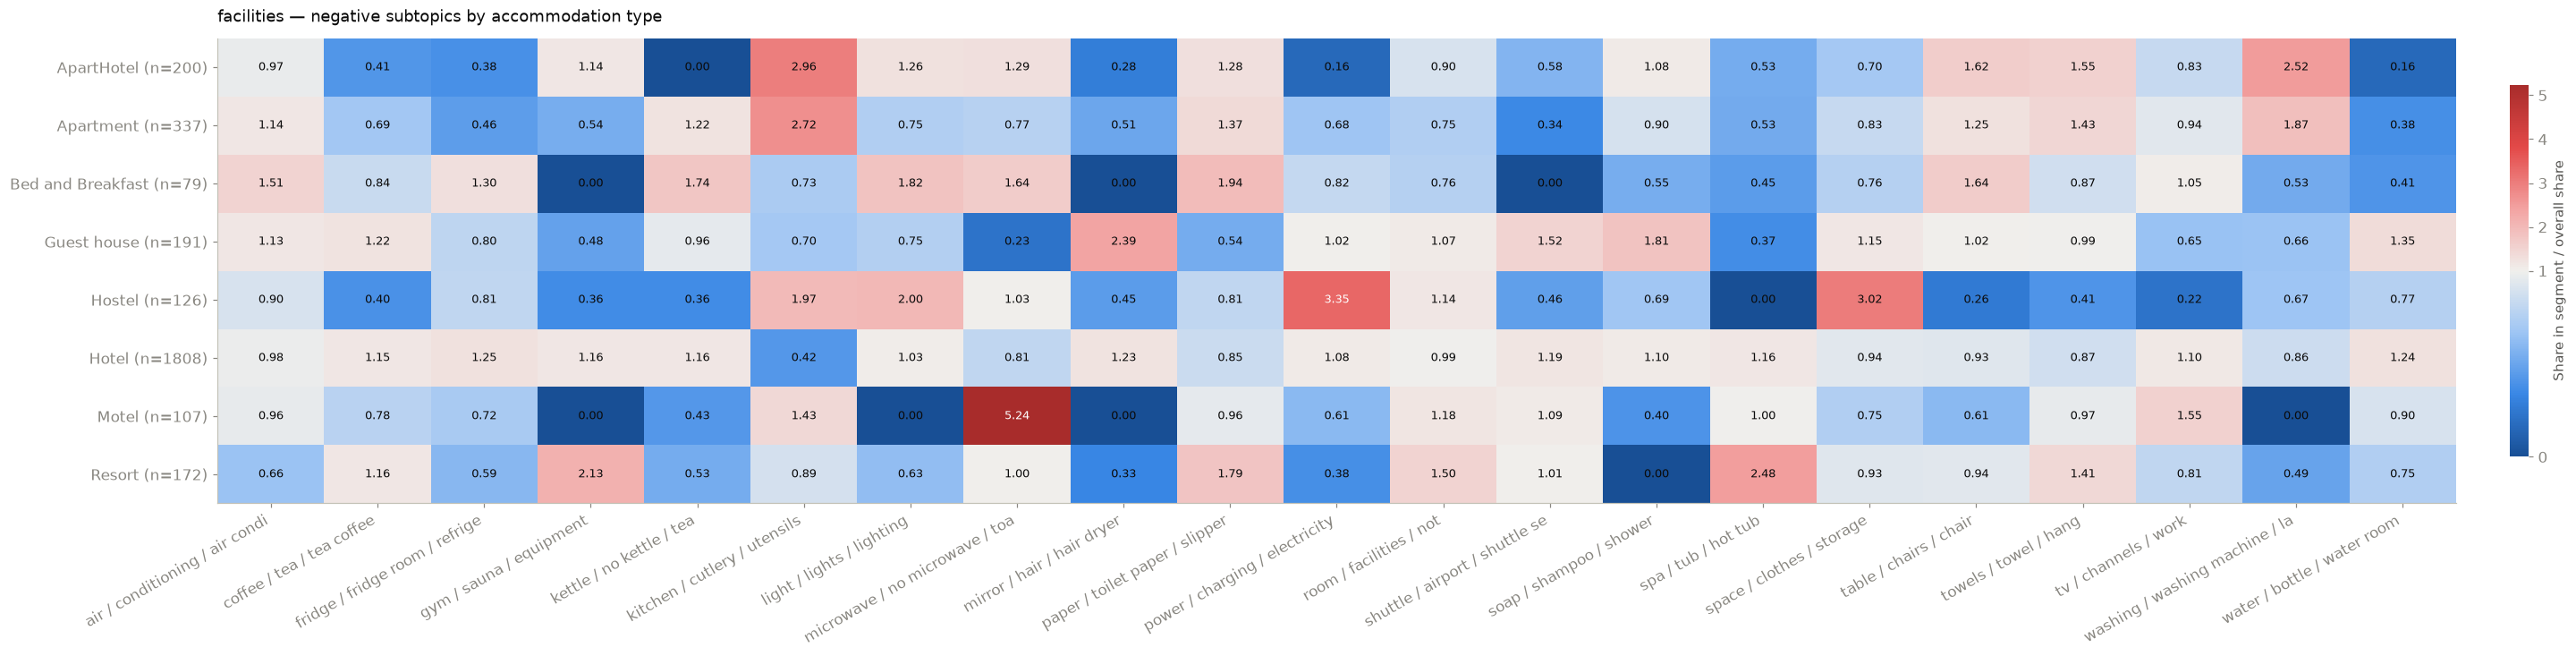

15:46:04 | INFO    | src.evaluation | Table saved: 05_negative_map_facilities_by_accommodation_country.csv
15:46:09 | INFO    | src.evaluation | Figure saved: 05_negative_map_facilities_by_accommodation_country.png


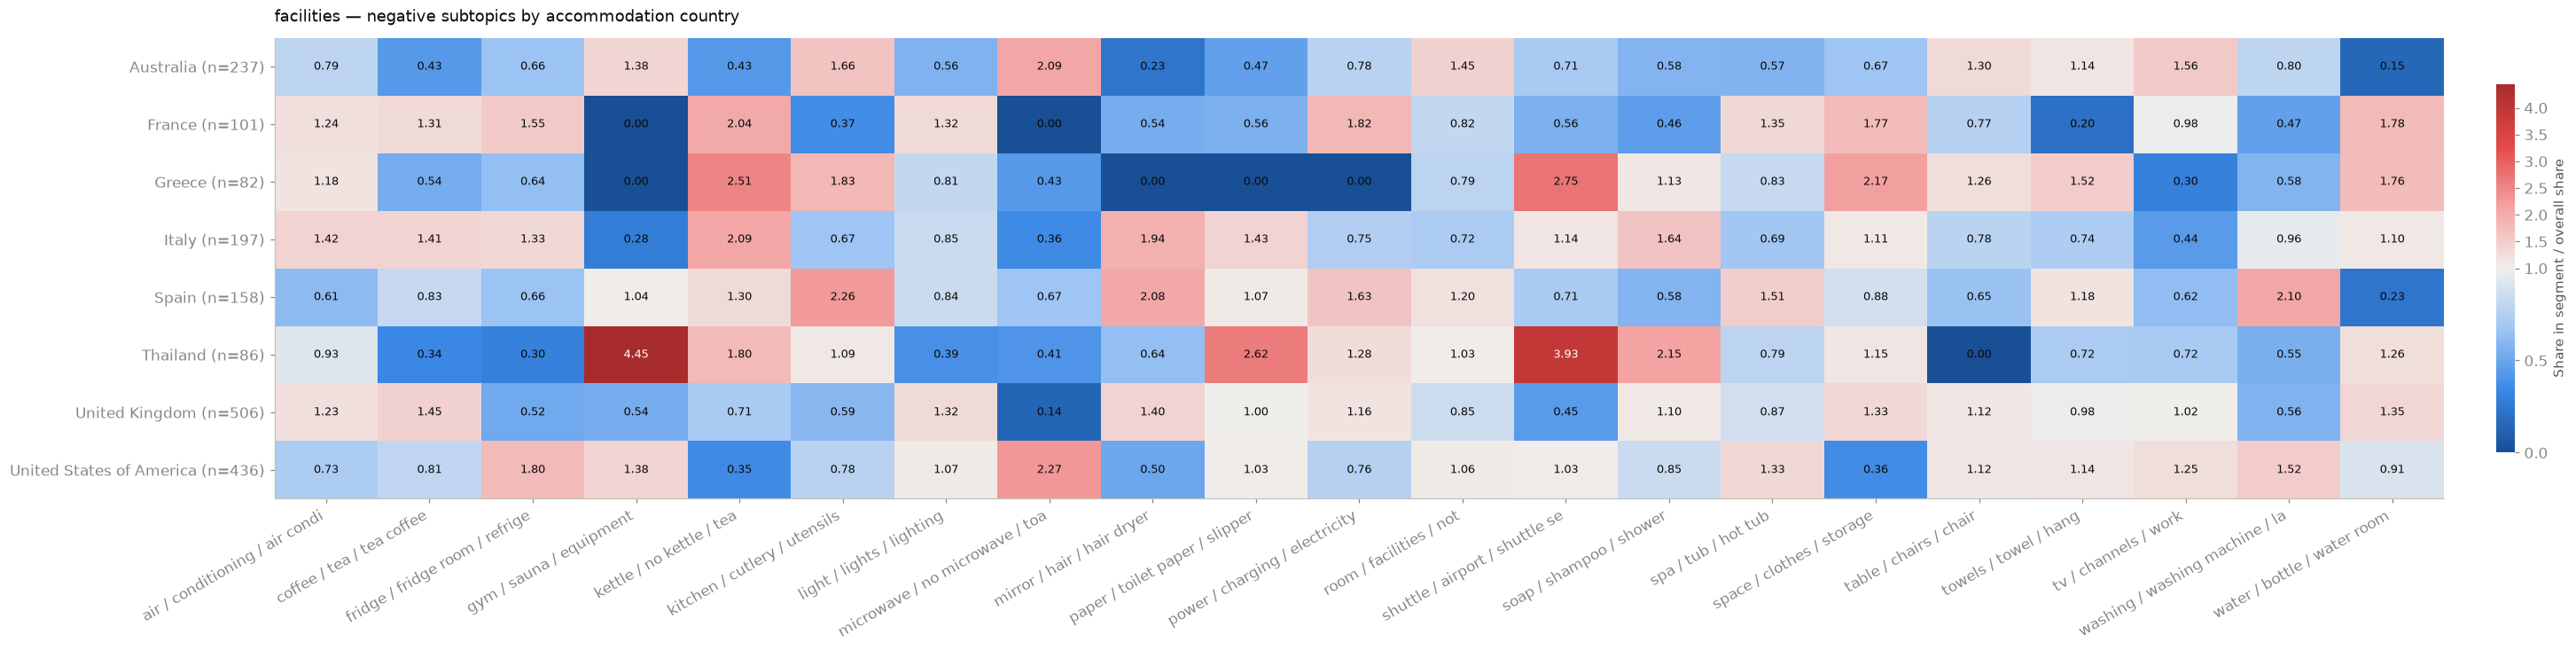

15:46:11 | INFO    | src.evaluation | Table saved: 05_negative_map_room_by_accommodation_type.csv
15:46:16 | INFO    | src.evaluation | Figure saved: 05_negative_map_room_by_accommodation_type.png


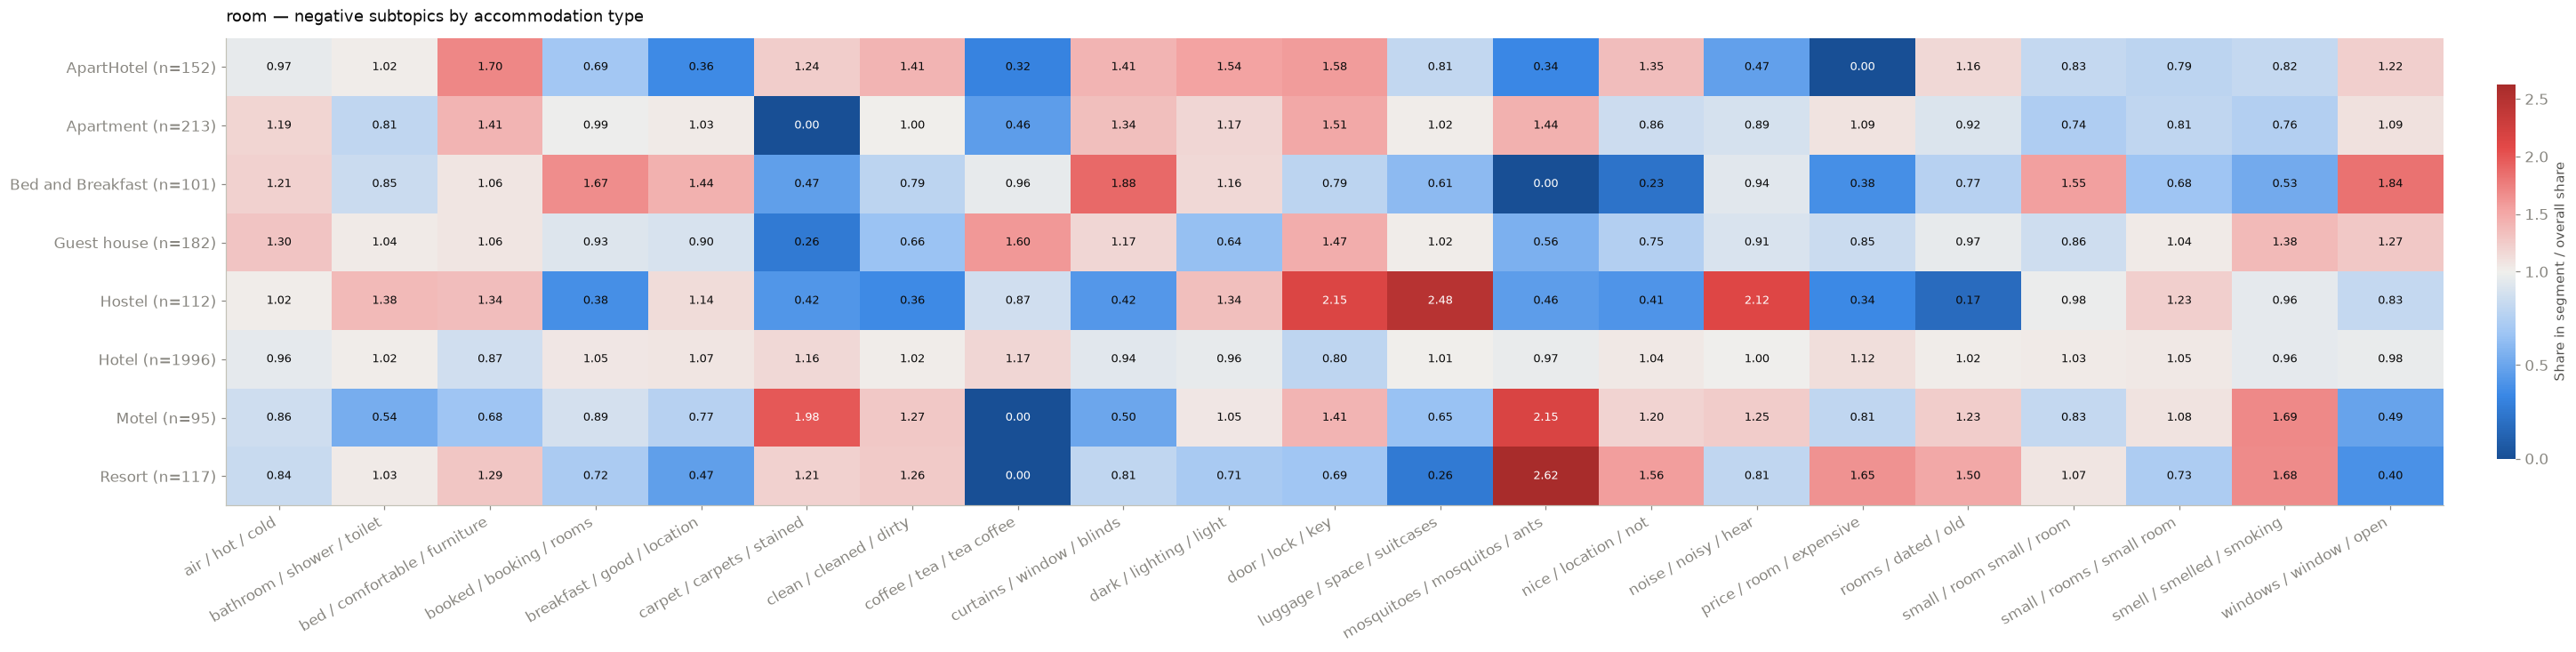

15:46:17 | INFO    | src.evaluation | Table saved: 05_negative_map_room_by_accommodation_country.csv
15:46:22 | INFO    | src.evaluation | Figure saved: 05_negative_map_room_by_accommodation_country.png


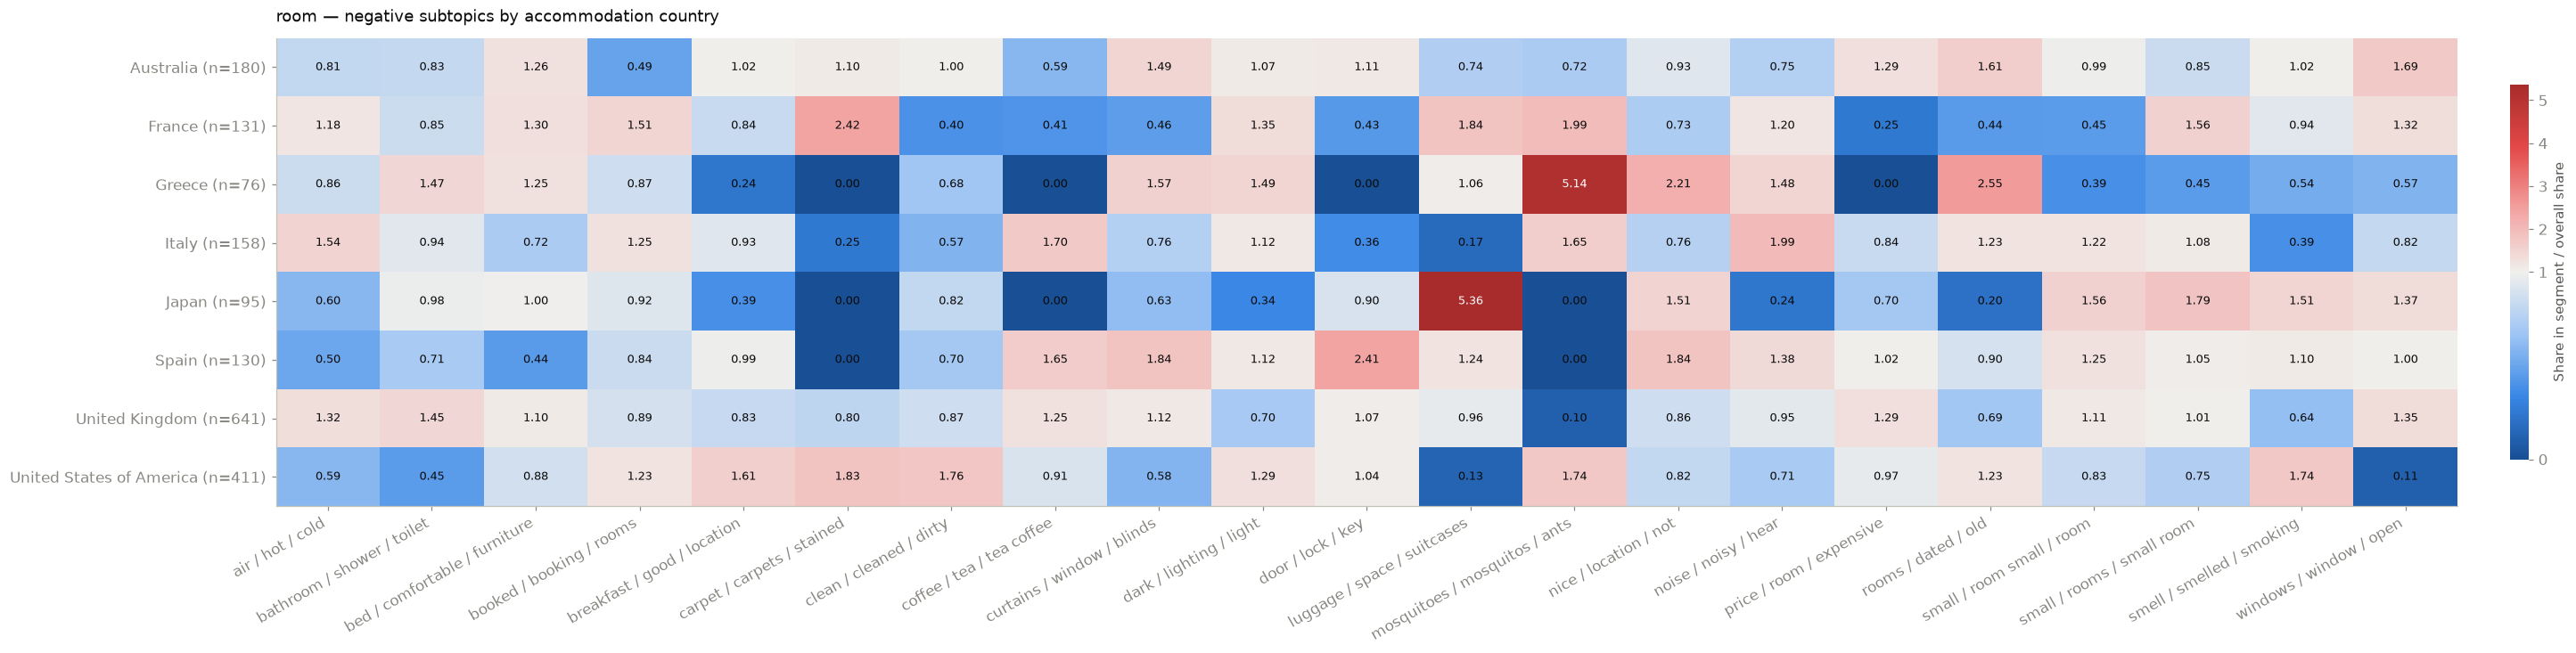

15:46:24 | INFO    | src.evaluation | Table saved: 05_negative_map_bathroom_by_accommodation_type.csv
15:46:27 | INFO    | src.evaluation | Figure saved: 05_negative_map_bathroom_by_accommodation_type.png


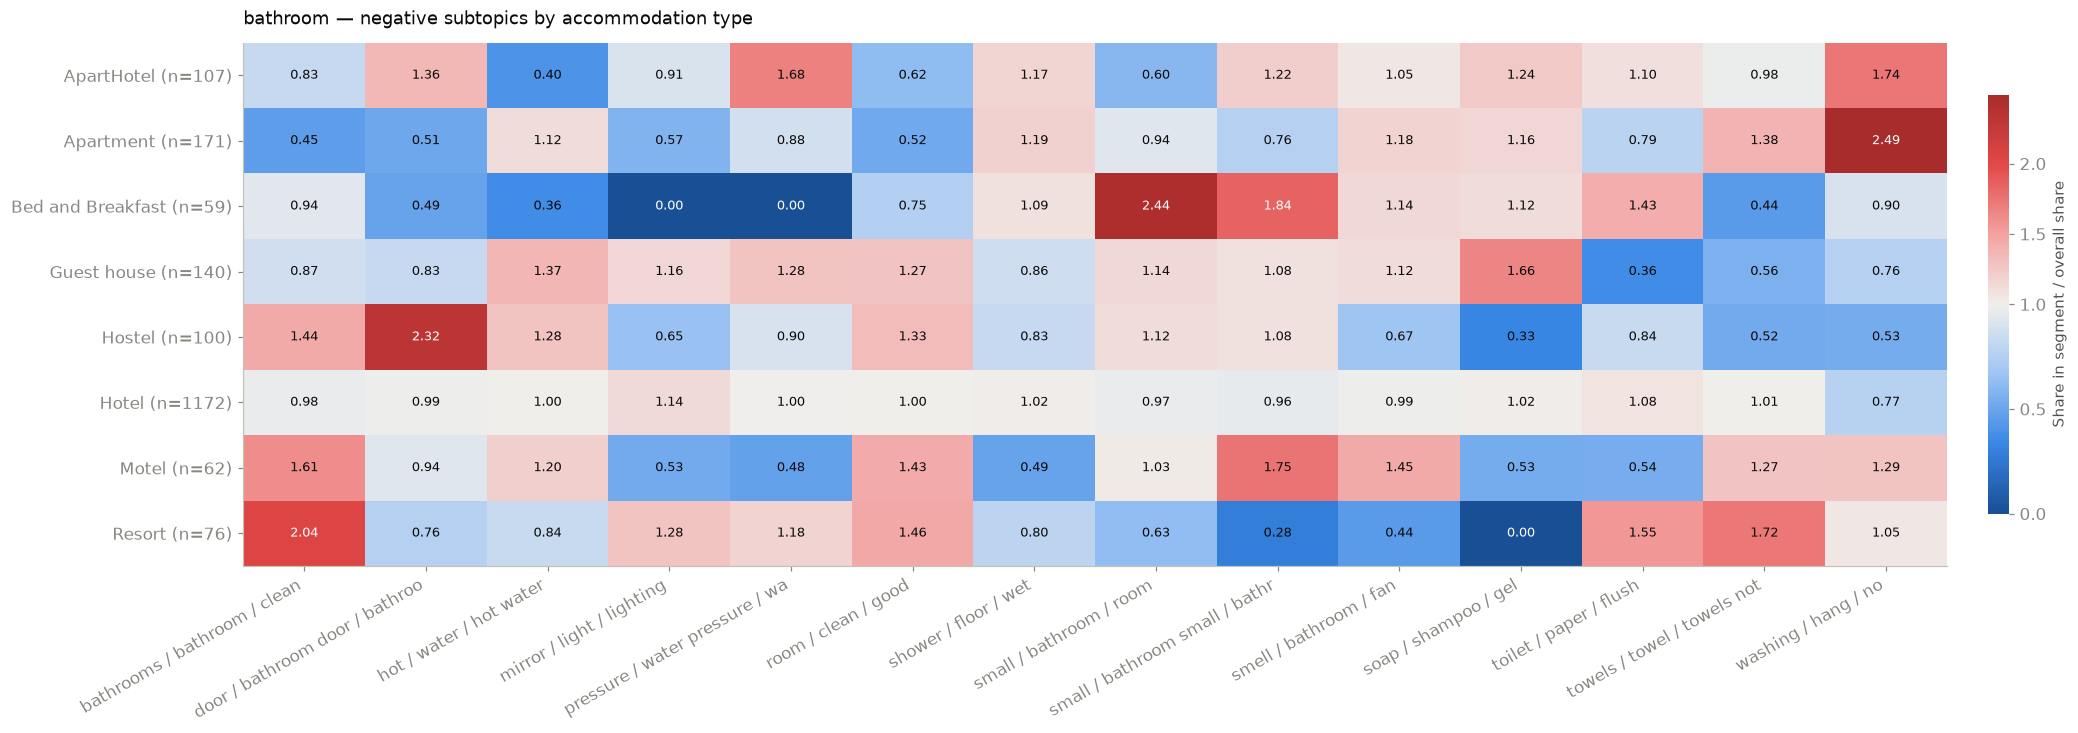

15:46:28 | INFO    | src.evaluation | Table saved: 05_negative_map_bathroom_by_accommodation_country.csv
15:46:32 | INFO    | src.evaluation | Figure saved: 05_negative_map_bathroom_by_accommodation_country.png


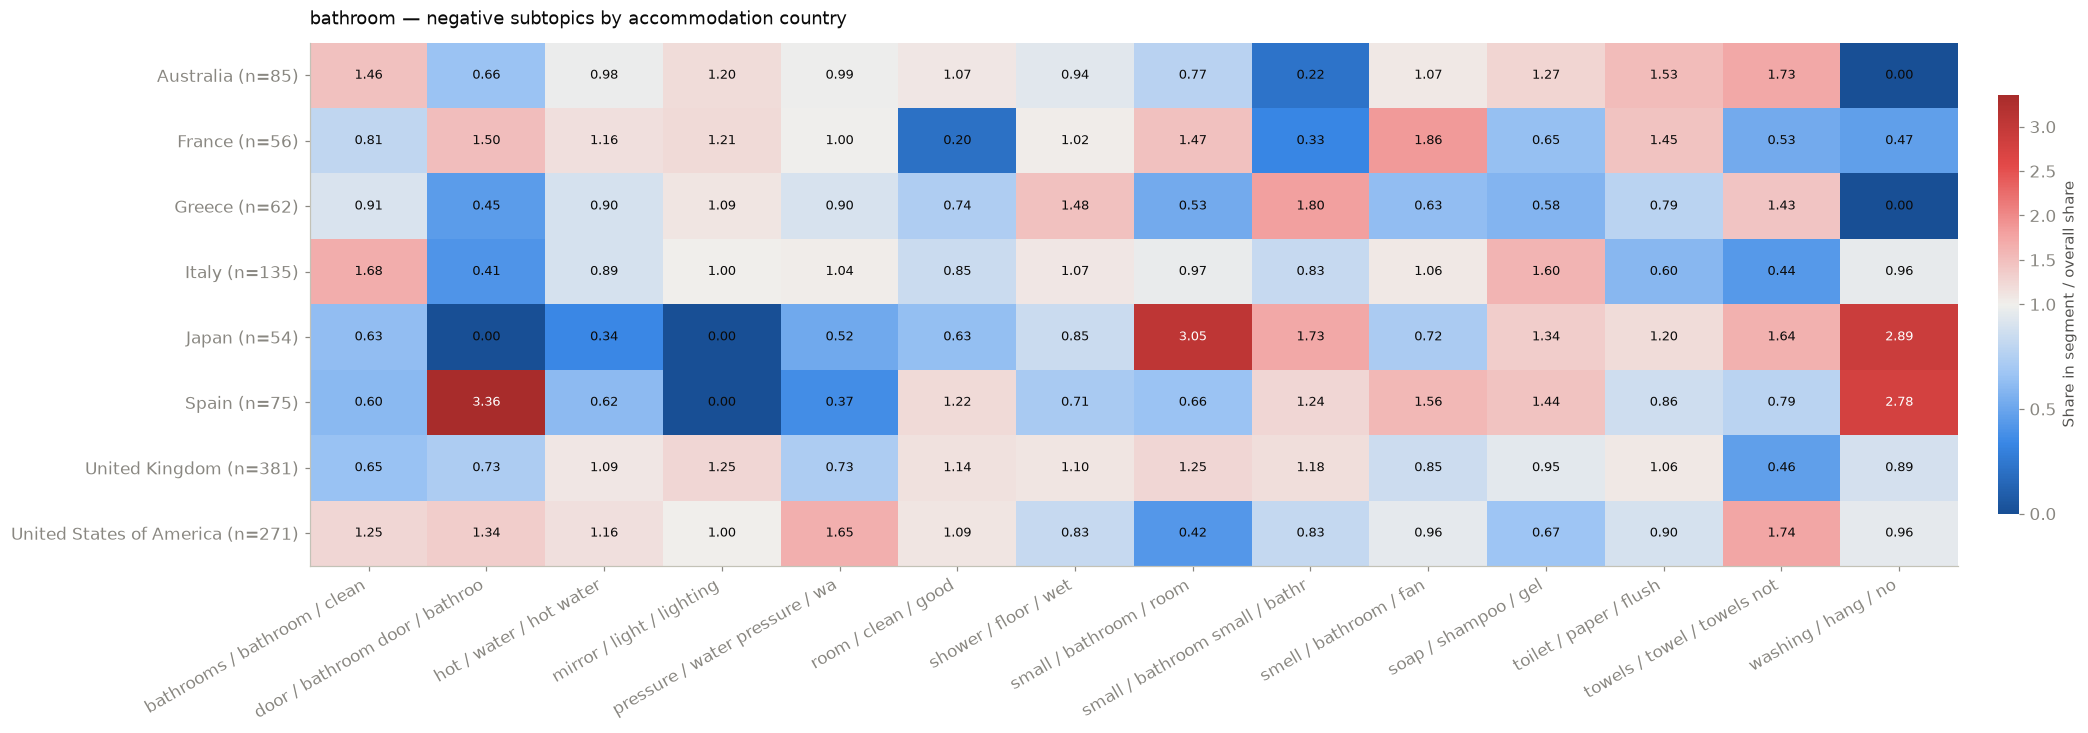

In [13]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        ev.save_table(lift, f"05_{SENTIMENT}_map_{aspect}_by_{segment}")
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{SENTIMENT}_map_{aspect}_by_{segment}")
        plt.show()

## 6. Kézi ellenőrzés / Manual check

HU: Témánként 20 véletlen mondat Excelben; a `fits` oszlopba 1 (illik a témához) vagy 0 kerül. Az első futás
exportál, a kitöltés után a második futás kiszámolja a témánkénti pontosságot. (Kb. 1–2 óra a nagyobb aspektusokra.)
EN: 20 random sentences per topic in Excel; put 1 (fits the topic) or 0 into the `fits` column. The first run exports,
after filling it in the second run computes the per-topic precision. (About 1–2 hours for the larger aspects.)

In [14]:
check_file = PATHS.annotation / f"topic_check_{SENTIMENT}.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    display(precision); ev.save_table(precision, f"05_{SENTIMENT}_topic_precision")

15:50:48 | INFO    | src.topic_modeling | Topic check exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\topic_check_negative.xlsx (1180 sentences)


Exported — fill in the 'fits' column, then re-run this cell.


---
## Összefoglalás / Summary

| Kimenet / Output | Mire jó? / Purpose |
|---|---|
| `05_aspect_keyword_vs_model` (tábla + ábra) | **2/a mérése:** tanult modell vs. kulcsszólista, emberi címkén |
| `05_aspect_model_test_report` | aspektusonkénti precision / recall / F1 |
| `05_aspect_sentiment_model` | aspektus × szentiment a tanult aspektusokkal |
| `05_<sentiment>_subtopics` + `_subtopics_by_aspect.png` | **2/b:** altémák aspektusonként |
| `05_<sentiment>_subtopic_quality`, `_stability` | koherencia, diverzitás, stabilitás |
| `05_<sentiment>_map_*` | **panasztérkép** szegmensenként |
| `05_<sentiment>_topic_precision` | kézi ellenőrzés: témánkénti pontosság |